In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/bm/v93fcqrd7kq6vwyfqyx20p5w0000gn/T/ipykernel_4311/3737875437.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

72 possible layouts


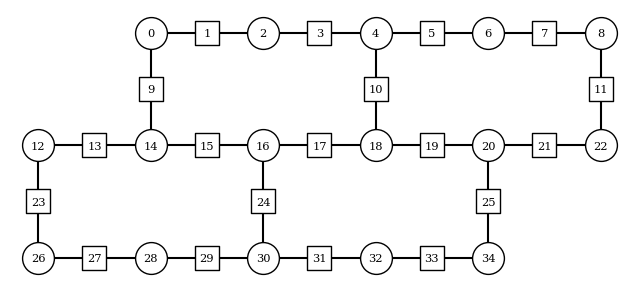

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

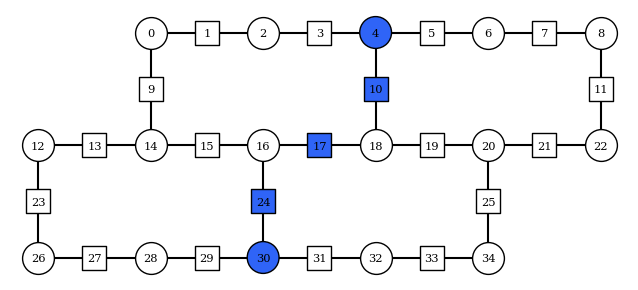

In [4]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

string = [4, 10, 17, 24, 30]
# string = [27, 26, 34, 43, 52, 60, 59]

final_time = 3
dt = 0.15
steps = 20
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 75000
confidence = 0.90

odr = True
postselect_odr = True
flip_threshold = 2
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True, filepath="z2hex_quench_initial_state.png")

# Circuit generation & observables

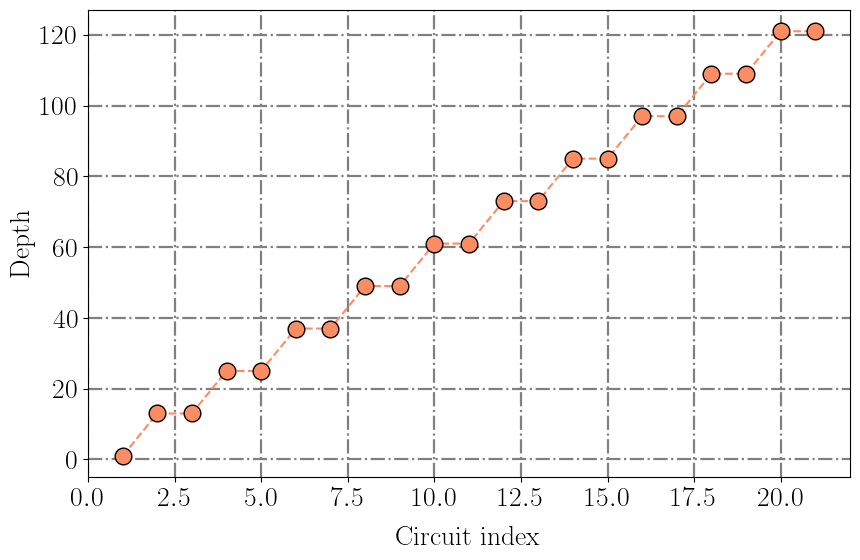

In [5]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, get_layouts
from z2hex.geometry import HeavyHexLattice, sort_layouts_by_func, measurement_decoherence_layout_cost
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

if all_or_first_layout_qubit == True:
    all_layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
    layouts = sort_layouts_by_func(all_layouts, lambda x: measurement_decoherence_layout_cost(x, backend))[:max_layouts]
elif isinstance(all_or_first_layout_qubit, int):
    layouts = [lattice.initial_qubit_layout(first_qubit=all_or_first_layout_qubit, backend=device)]
else:
    layouts = None
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, False)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    circuits, odr_circuits = simulation_and_odr_circuits(*circs_args)
else:
    circuits = simulation_and_odr_circuits(*circs_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_circuit_arr_depth(circuits[0])

# Load TN data

In [6]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 16
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limit = int(final_time / tn_dt)

tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_BUG_g{h:.02f}_m{J:.02f}_ROWS2_COLS2_dt{tn_dt:.03f}_Tmax{tn_final_time:.02f}_exp_order{tn_exp_order}_M{tn_bond_dimension:05d}.txt")
tn_observables = np.loadtxt(tn_data_filepath)

# Load jobs

In [7]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

overwrite = False
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
else:
    curated_data_filepath = ""

if overwrite or not os.path.exists(curated_data_filepath):
    if odr:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
    else:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
    if curated_data_filepath is not None:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

# Different flip thresholds

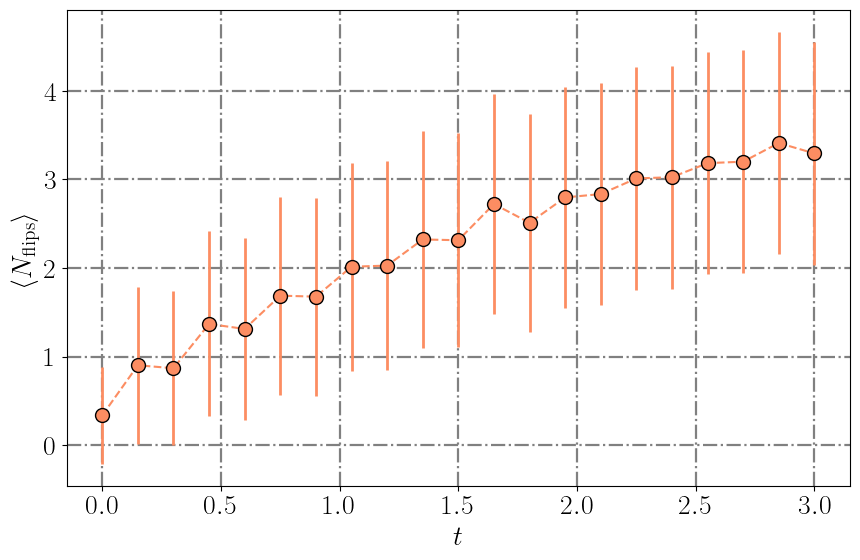

In [8]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
import matplotlib.pyplot as plt
from pymatching import Matching

plot_filepath = f"z2hex_quench_nflips_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
decoder = Matching(postselection_mask)

distribution_means = np.zeros(steps+1)
standard_distributions = np.zeros(steps+1)
for i in range(steps+1):
    all_layouts_samples_dicts = [samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
    if combined_samples_dict == {}:
        distribution_means[i] = np.nan
        standard_distributions[i] = np.nan
    else:
        states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
        state_counts = np.array(list(combined_samples_dict.values()))
        states_syndromes = (states @ postselection_mask.T) % 2
        predicted_flips = decoder.decode_batch(states_syndromes)
        nflips = predicted_flips.sum(axis=1)
        unique_nflips = np.unique(nflips)
        this_flip_counts = {}
        this_total_nflips = 0
        for nf in unique_nflips:
            this_counts = np.sum(state_counts[np.equal(nflips, nf)])
            this_flip_counts[nf] = this_counts
            this_total_nflips += this_counts
        this_mean = 0
        for nf, counts in this_flip_counts.items():
            this_mean += nf*counts/this_total_nflips
        distribution_means[i] = this_mean
        for nf, counts in this_flip_counts.items():
            standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
        standard_distributions[i] = np.sqrt(standard_distributions[i])

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])

x = np.linspace(0, final_time, steps+1)
x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

plt.errorbar(x, distribution_means, yerr=standard_distributions, fmt="o--", color=plt.get_cmap("Set2")(1), markersize=10, elinewidth=2, markeredgecolor="black")
plt.xlabel(r"$t$")
plt.ylabel(r"$\langle N_{\mathrm{flips}} \rangle$")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.tight_layout()
plt.savefig(plot_filepath)
plt.rcdefaults()

In [31]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

overwrite = True
flip_thresholds = [1, 2, 3, 4, 5, 6]

datas = []
for ft in flip_thresholds:
    print(f"ft = {ft}")
    if curated_data_folder_path is not None:
        curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{ft}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
    else:
        curated_data_filepath = ""

    if overwrite or not os.path.exists(curated_data_filepath):
        if odr:
            observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=ft, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
        else:
            observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=ft, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
        data = (observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts)
        if curated_data_filepath is not None:
            with open(curated_data_filepath, "wb") as f:
                pickle.dump(data, f)
    else:
        with open(curated_data_filepath, "rb") as f:
            data = pickle.load(f)
    datas.append(data)

ft = 1
Loaded 21 jobs                                                                                     
ft = 2
Loaded 21 jobs                                                                                     
ft = 3
Loaded 21 jobs                                                                                     
ft = 4
Loaded 21 jobs                                                                                     
ft = 5
Loaded 21 jobs                                                                                     
ft = 6
Loaded 21 jobs                                                                                     


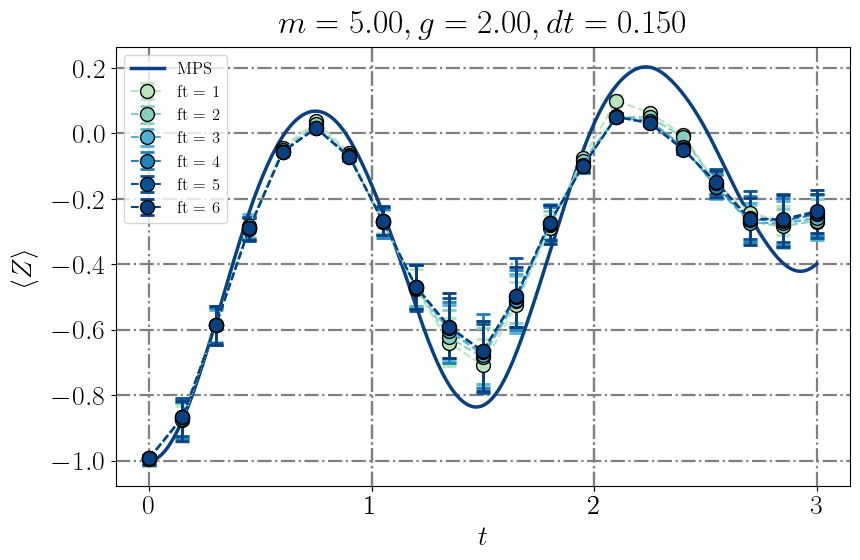

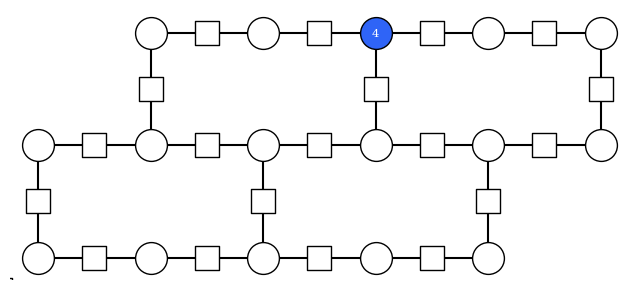

In [33]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 4

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+2.5)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [rf"ft = ${ft}$" for ft in flip_thresholds] + ["MPS"]

plot_filepath = f"z2hex_quench_ft_comparison_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_ft_comparison_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(datas), 2))
for i, hdata in enumerate(datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

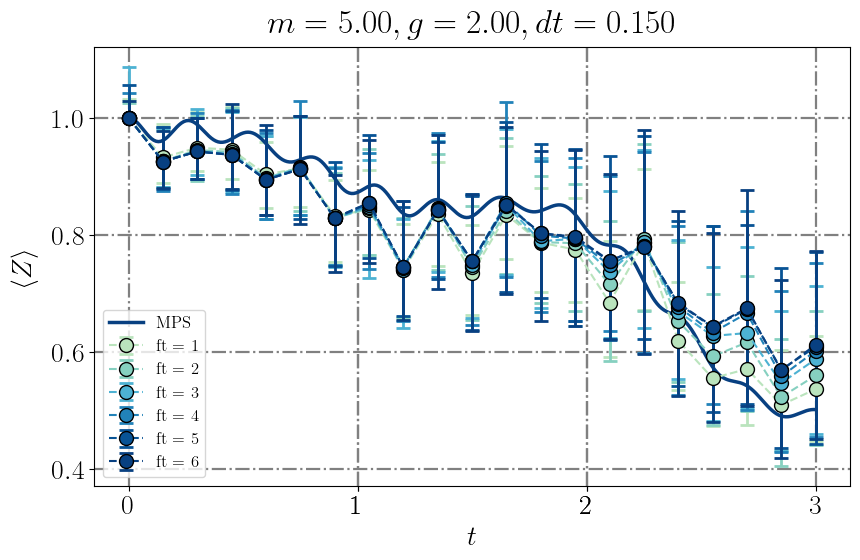

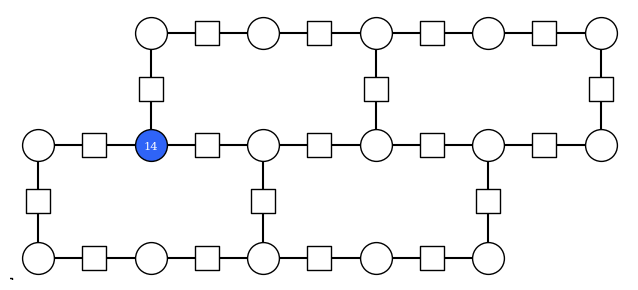

In [35]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 14

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+2.5)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [rf"ft = ${ft}$" for ft in flip_thresholds] + ["MPS"]

plot_filepath = f"z2hex_quench_ft_comparison_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_ft_comparison_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(datas), 2))
for i, hdata in enumerate(datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

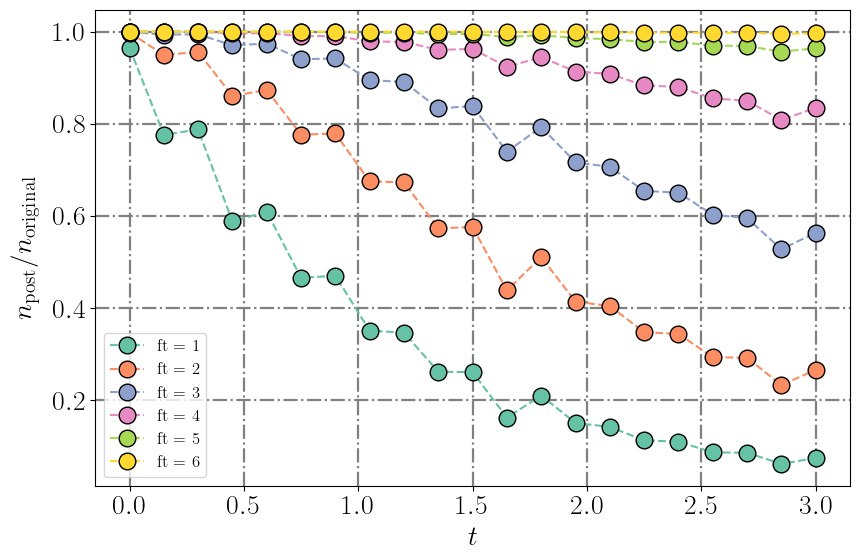

In [34]:
from utils.plotting import plot_discarded_samples

x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"

funclabels = [rf"ft = ${ft}$" for ft in flip_thresholds]

plot_filepath = f"z2hex_quench_ft_shotcount_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

samples_dicts = [data[2][0][0] for data in datas]
postselected_samples_dicts = [data[3][0][0] for data in datas]

plot_discarded_samples(postselected_samples_dicts, samples_dicts, x_ticks=x_ticks, x_label=x_label, labels=funclabels, filepath=plot_filepath)

# Different minimum shots

In [18]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

overwrite = False
flip_threshold = 2
minimum_shots = [5000, 10000, 20000, 30000, 40000, 70000]

datas = []
for ms in minimum_shots:
    print(f"minimum_shots = {ms}")
    if curated_data_folder_path is not None:
        curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_ms_{ms}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
    else:
        curated_data_filepath = ""

    if overwrite or not os.path.exists(curated_data_filepath):
        if odr:
            observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, minimum_shots=ms, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
        else:
            observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, minimum_shots=ms, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
        data = (observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts)
        if curated_data_filepath is not None:
            with open(curated_data_filepath, "wb") as f:
                pickle.dump(data, f)
    else:
        with open(curated_data_filepath, "rb") as f:
            data = pickle.load(f)
    datas.append(data)

minimum_shots = 5000
minimum_shots = 10000
minimum_shots = 20000
minimum_shots = 30000
minimum_shots = 40000
minimum_shots = 70000


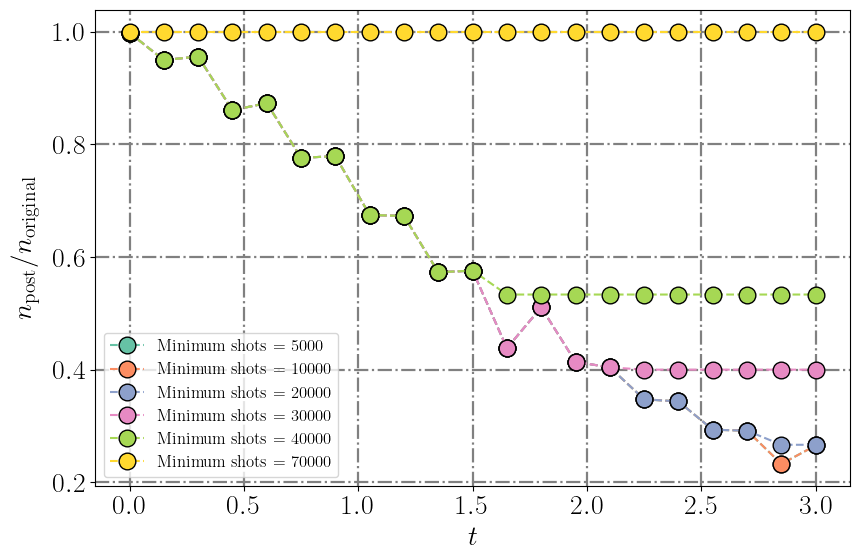

In [20]:
from utils.plotting import plot_discarded_samples

x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"

funclabels = [rf"Minimum shots = ${ms}$" for ms in minimum_shots]

plot_filepath = f"z2hex_quench_ms_shotcount_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

samples_dicts = [data[2][0][0] for data in datas]
postselected_samples_dicts = [data[3][0][0] for data in datas]

plot_discarded_samples(postselected_samples_dicts, samples_dicts, x_ticks=x_ticks, x_label=x_label, labels=funclabels, filepath=plot_filepath)

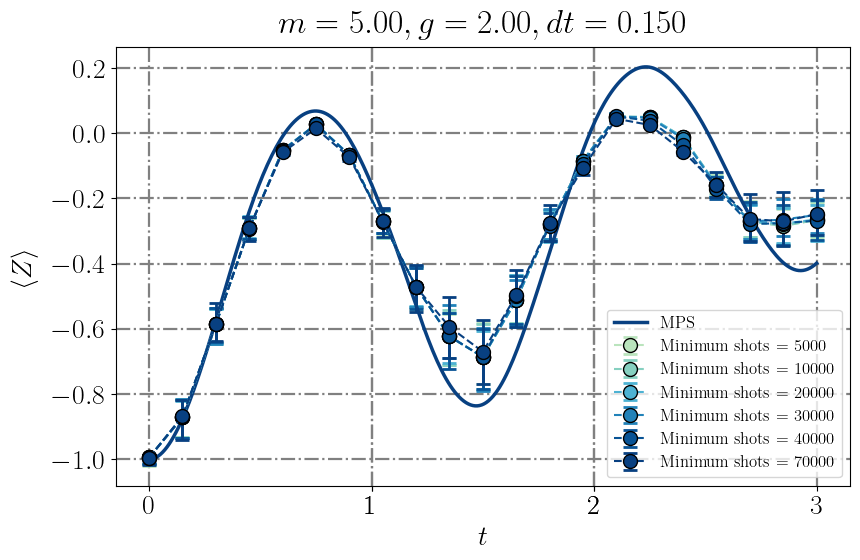

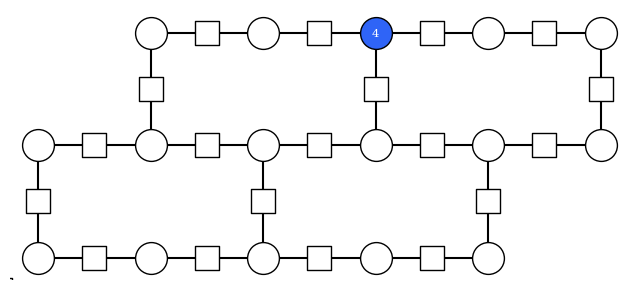

In [26]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 4

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+2.5)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [rf"Minimum shots = ${ms}$" for ms in minimum_shots] + ["MPS"]

plot_filepath = f"z2hex_quench_ms_comparison_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_ms_comparison_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(datas), 2))
for i, hdata in enumerate(datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

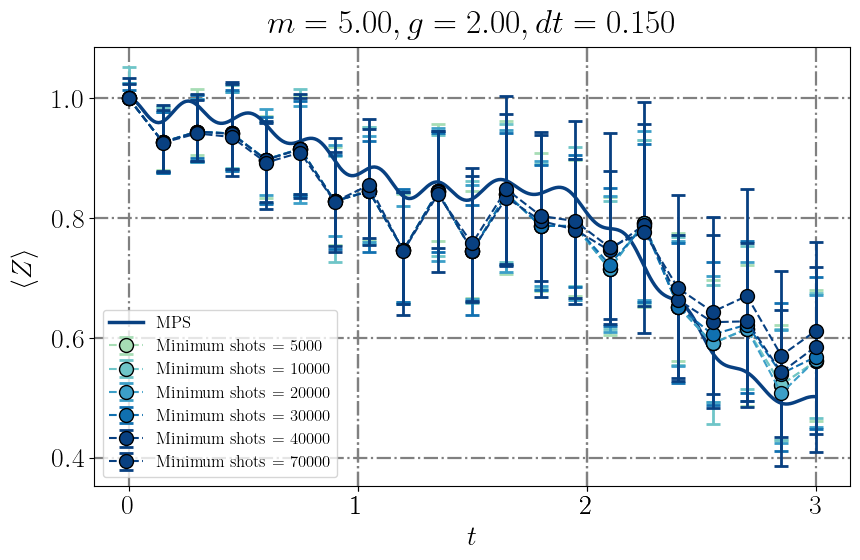

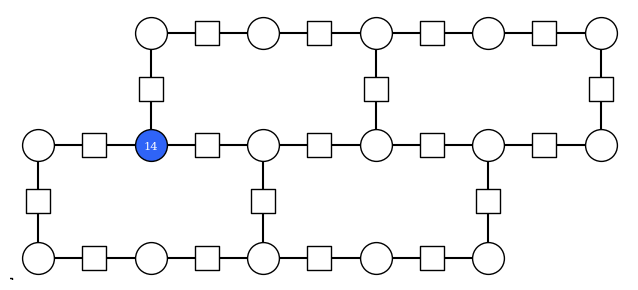

In [27]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

# qubit = 20
qubit = 14

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [rf"Minimum shots = ${ms}$" for ms in minimum_shots] + ["MPS"]

plot_filepath = f"z2hex_quench_ms_comparison_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_ms_comparison_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(datas), 2))
for i, hdata in enumerate(datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

# Different ODR strategies

In [17]:
from utils.postselection_multithreaded import load_postselected_jobs_obs, load_postselected_jobs_inverse_order
import pickle
import os

overwrite = False
load_functions = [load_postselected_jobs_obs, load_postselected_jobs_inverse_order]
filenames = [
    f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_ms_{ms}_pODR_{postselect_odr}_confidence_{confidence}.pkl",
    f"z2hexquench_curated_data_inverse_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_ms_{ms}_pODR_{postselect_odr}_confidence_{confidence}.pkl"
]

datas = []
for lf, filename in zip(load_functions, filenames):
    if curated_data_folder_path is not None:
        curated_data_filepath = os.path.join(curated_data_folder_path, filename)
    else:
        curated_data_filepath = ""

    if overwrite or not os.path.exists(curated_data_filepath):
        if odr:
            observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = lf(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
        else:
            observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = lf(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
        data = (observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts)
        if curated_data_filepath is not None:
            with open(curated_data_filepath, "wb") as f:
                pickle.dump(data, f)
    else:
        with open(curated_data_filepath, "rb") as f:
            data = pickle.load(f)
    datas.append(data)

Loaded 21 jobs                                                                                     
Loaded 21 jobs                                                                                     


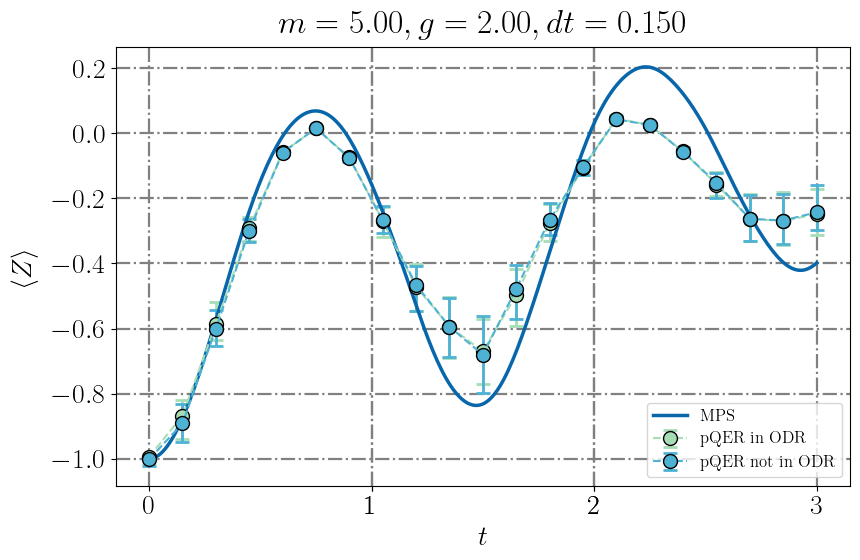

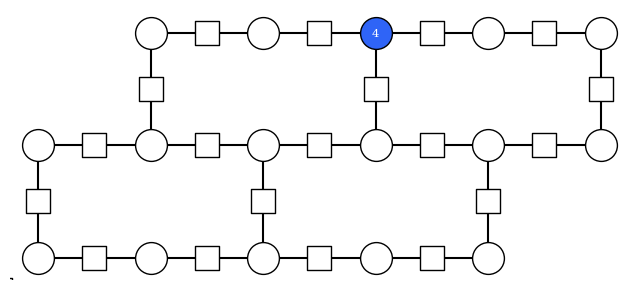

In [18]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 4

cmap = lambda x: plt.get_cmap("GnBu")((2*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = ["pQER in ODR", "pQER not in ODR"] + ["MPS"]

plot_filepath = f"z2hex_quench_dec_order_comparison_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_dec_order_comparison_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(datas), 2))
for i, hdata in enumerate(datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

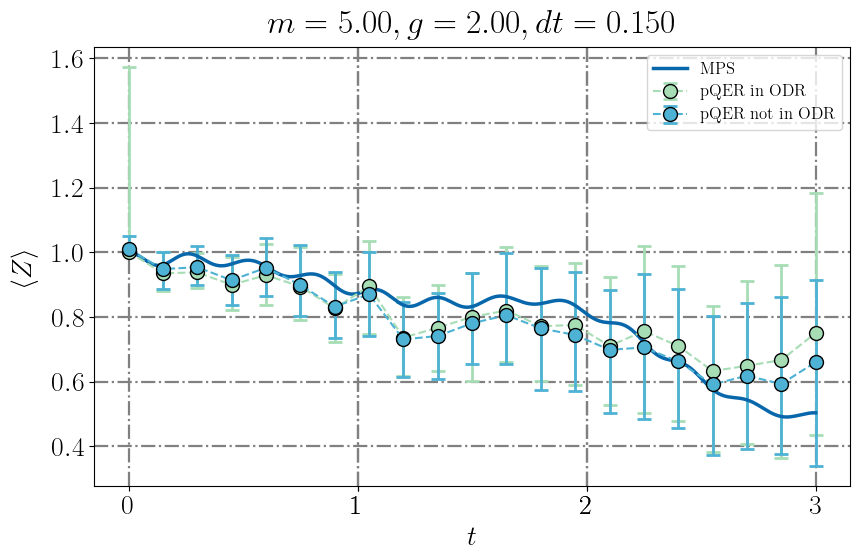

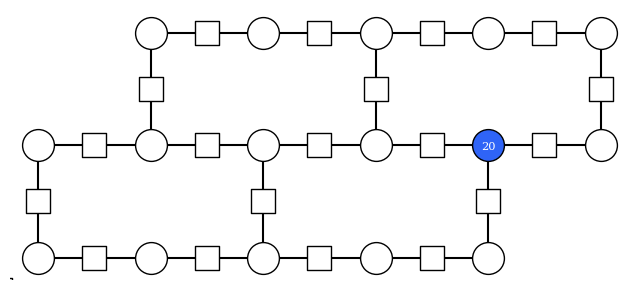

In [19]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 20

cmap = lambda x: plt.get_cmap("GnBu")((2*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = ["pQER in ODR", "pQER not in ODR"] + ["MPS"]

plot_filepath = f"z2hex_quench_dec_order_comparison_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_dec_order_comparison_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][0][:, qubit] for hdata in datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(datas), 2))
for i, hdata in enumerate(datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)